In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 18.6 — Quasitriangular Hopf algebras

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Equations (18.34)–(18.42), (18.48), (18.50). First (18.38)–(18.39): $R$ is a state $1\to H\otimes H$, whereas the unit $\eta$ is a state $1\to H$. Inserting a unit wire and swapping places it in the middle. This diagram is inferred directly from the displayed tensor expressions.

In [1]:
from discopy import symmetric
H = symmetric.Ty('H')
eta = symmetric.Box('eta', symmetric.Ty(), H)
R = symmetric.Box('R', symmetric.Ty(), H @ H)
R12 = R @ eta
R23 = eta @ R
R13_left = R23 >> (symmetric.Swap(H, H) @ symmetric.Id(H))
R13_right = R12 >> (symmetric.Id(H) @ symmetric.Swap(H, H))
print('18.39 first expression:', R13_left)
print('18.39 second expression:', R13_right)
print('Both expected boundary 1 -> H @ H @ H:', R13_left.dom == R13_right.dom == symmetric.Ty() and R13_left.cod == R13_right.cod == H @ H @ H)

18.39 first expression: eta >> H @ R >> Swap(H, H) @ H
18.39 second expression: R >> H @ H @ eta >> H @ Swap(H, H)
Both expected boundary 1 -> H @ H @ H: True


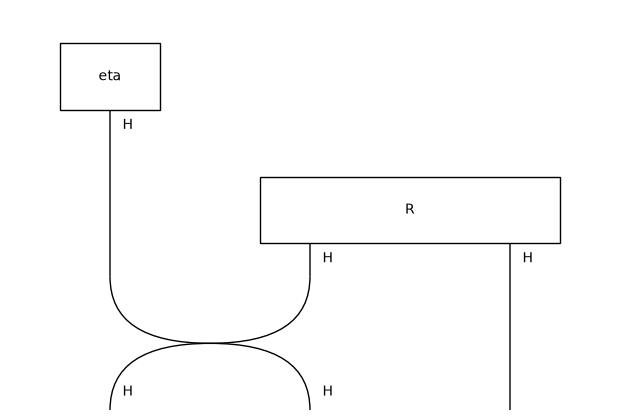

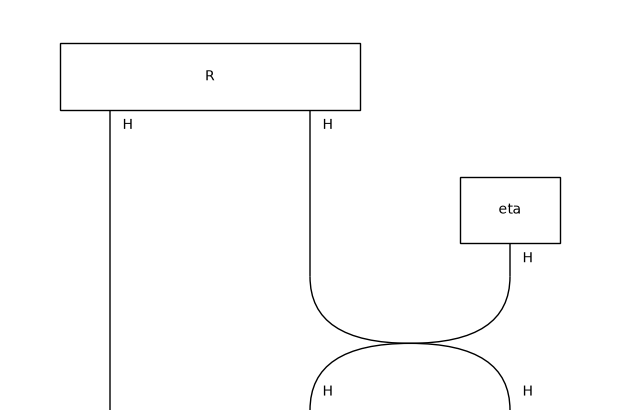

In [2]:
R13_left.draw(figsize=(6, 4))
R13_right.draw(figsize=(6, 4))

Evaluate (18.39) using precisely the $\mathbb{F}\mathbb{Z}_2$ element in (18.41), in the ordered basis $(\beta_e,\beta_g)$. The half-integer entries are exact binary floating-point numbers here; this check only concerns placement of tensor factors.

In [3]:
from discopy import tensor
F = tensor.Functor({H: 2}, {eta: [1, 0], R: [0.5, 0.5, 0.5, -0.5]}, dom=symmetric.Category(), dtype=float)
print('18.39 first expression entries:')
print(F(R13_left).array)
print('Second expression entries:')
print(F(R13_right).array)
print('Equal in source Z2 example:', F(R13_left) == F(R13_right))

18.39 first expression entries:
[[[ 0.5  0.5]
  [ 0.   0. ]]

 [[ 0.5 -0.5]
  [ 0.   0. ]]]
Second expression entries:
[[[ 0.5  0.5]
  [ 0.   0. ]]

 [[ 0.5 -0.5]
  [ 0.   0. ]]]
Equal in source Z2 example: True


**The quasitriangular laws, Definitions 18.6.2 and 18.6.5.** An element $R\in H\otimes H$ is a universal $R$-matrix when it is invertible, satisfies $(\tau\circ\Delta(x))\cdot R=R\cdot\Delta(x)$ for every $x$, equation (18.35), and the two factorization laws (18.36), $(\Delta\otimes\mathrm{id})(R)=R_{13}R_{23}$ and $(\mathrm{id}\otimes\Delta)(R)=R_{13}R_{12}$. A product of two elements of $H\otimes H$ is a diagram too: put the two states side by side, cross the middle wires so that matching factors are adjacent, and multiply pairwise with $\mu\otimes\mu$; for three factors, two more crossings and $\mu\otimes\mu\otimes\mu$. Two examples are evaluated. The first is SMSA's (18.41), the group algebra of $\mathbb Z_2$. The second is the changed example $\mathbb Z_3$ with a primitive cube root of unity $\omega$ and $R=\tfrac13\sum_{i,j}\omega^{ij}\,g^i\otimes g^j$, which reduces to (18.41) for $n=2$, $\omega=-1$. Both group algebras are cocommutative, (18.34), so (18.35) holds for any $R$ whatsoever and these examples cannot test it; the laws (18.36) and invertibility are real tests, as the all-ones control shows. Invertibility is checked by multiplying $R$ with $(s\otimes\mathrm{id})(R)$, a candidate inverse supplied here as data; the diagrams do not derive that formula.

first law : Ty() -> H @ H @ H  and  Ty() -> H @ H @ H
second law: Ty() -> H @ H @ H  and  Ty() -> H @ H @ H


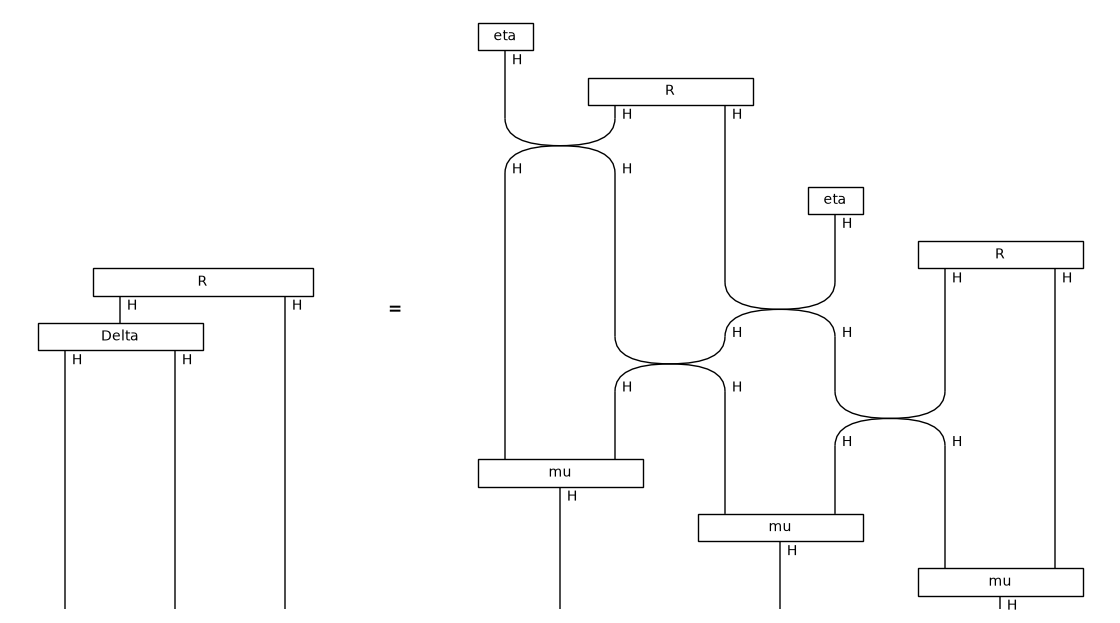

In [4]:
import numpy as np
from discopy.drawing import Equation
I = symmetric.Id(H)
Sw = symmetric.Swap(H, H)
mu = symmetric.Box('mu', H @ H, H)
Delta = symmetric.Box('Delta', H, H @ H)
epsilon = symmetric.Box('epsilon', H, symmetric.Ty())
s = symmetric.Box('s', H, H)
times2 = (I @ Sw @ I) >> (mu @ mu)                                        # product in H x H
perm6 = (symmetric.Id(H @ H) @ Sw @ symmetric.Id(H @ H)) >> (I @ Sw @ symmetric.Id(H @ H @ H)) >> (symmetric.Id(H @ H @ H) @ Sw @ I)
times3 = perm6 >> (mu @ mu @ mu)                                          # product in H x H x H
R13 = R23 >> (Sw @ I)
law1_left, law1_right = R >> (Delta @ I), (R13 @ R23) >> times3           # (18.36), first law
law2_left, law2_right = R >> (I @ Delta), (R13 @ R12) >> times3           # (18.36), second law
R_inverse = R >> (s @ I)                                                  # candidate inverse (s x id)(R)
one = eta @ eta
print('first law :', law1_left.dom, '->', law1_left.cod, ' and ', law1_right.dom, '->', law1_right.cod)
print('second law:', law2_left.dom, '->', law2_left.cod, ' and ', law2_right.dom, '->', law2_right.cod)
Equation(law1_left, law1_right, symbol='=').draw(figsize=(11, 6))

In [5]:
examples = [(2, -1.0, 'Z2, equation (18.41)'), (3, np.exp(2j * np.pi / 3), 'Z3 with omega = exp(2 pi i / 3)')]
for n, omega, label in examples:
    mu_arr = [[[int(k == (i + j) % n) for k in range(n)] for j in range(n)] for i in range(n)]
    Delta_arr = [[[int(i == j == k) for k in range(n)] for j in range(n)] for i in range(n)]
    s_arr = [[int(j == (-i) % n) for j in range(n)] for i in range(n)]
    R_arr = [[omega ** (i * j) / n for j in range(n)] for i in range(n)]
    Fn = tensor.Functor({H: n}, {mu: mu_arr, eta: [int(k == 0) for k in range(n)], Delta: Delta_arr, epsilon: [1] * n, s: s_arr, R: R_arr}, dom=symmetric.Category(), dtype=complex)
    print('####', label)
    print('(18.34) cocommutative, tau o Delta == Delta:', np.allclose(Fn(Delta >> Sw).array, Fn(Delta).array), '  so (18.35) cannot fail in this example')
    print('(18.36) (Delta x id)(R) == R13 R23:', np.allclose(Fn(law1_left).array, Fn(law1_right).array))
    print('(18.36) (id x Delta)(R) == R13 R12:', np.allclose(Fn(law2_left).array, Fn(law2_right).array))
    print('R (s x id)(R) == 1 x 1:', np.allclose(Fn((R @ R_inverse) >> times2).array, Fn(one).array), '  (s x id)(R) R == 1 x 1:', np.allclose(Fn((R_inverse @ R) >> times2).array, Fn(one).array))
    Fbad = tensor.Functor({H: n}, {mu: mu_arr, eta: [int(k == 0) for k in range(n)], Delta: Delta_arr, s: s_arr, R: [[1 / n for j in range(n)] for i in range(n)]}, dom=symmetric.Category(), dtype=complex)
    print('control with all entries 1/n: (18.36) first law:', np.allclose(Fbad(law1_left).array, Fbad(law1_right).array), '  invertible by (s x id):', np.allclose(Fbad((R @ R_inverse) >> times2).array, Fbad(one).array))

#### Z2, equation (18.41)
(18.34) cocommutative, tau o Delta == Delta: True   so (18.35) cannot fail in this example
(18.36) (Delta x id)(R) == R13 R23: True
(18.36) (id x Delta)(R) == R13 R12: True
R (s x id)(R) == 1 x 1: True   (s x id)(R) R == 1 x 1: True
control with all entries 1/n: (18.36) first law: False   invertible by (s x id): False
#### Z3 with omega = exp(2 pi i / 3)
(18.34) cocommutative, tau o Delta == Delta: True   so (18.35) cannot fail in this example
(18.36) (Delta x id)(R) == R13 R23: True
(18.36) (id x Delta)(R) == R13 R12: True
R (s x id)(R) == 1 x 1: True   (s x id)(R) R == 1 x 1: True
control with all entries 1/n: (18.36) first law: False   invertible by (s x id): False


**Monodromy matrix and Drinfeld map, (18.48) and (18.50).** The monodromy element is $Q=\tau(R)\cdot R$, the flipped $R$ multiplied by $R$ in $H\otimes H$. The Drinfeld map $(\mathrm{ev}_H\otimes\mathrm{id}_H)\circ(\mathrm{id}_{H^*}\otimes Q)$ takes a covector $f\in H^*$, feeds it into the first leg of $Q$ with a cup, and leaves the second leg as the output in $H$. With $H^*$ the type `H.l` as in §2.5 this is one cup next to the state $Q$. The cells print $Q$ and the matrix of the Drinfeld map for both examples. For $\mathbb Z_2$ with (18.41), $Q=1\otimes1$, so the Drinfeld map sends every $f$ to $f(1)\cdot1$ and has rank one. For $\mathbb Z_3$ with $\omega$, $Q\neq1\otimes1$ and the Drinfeld map is invertible. SMSA's notion of a factorizable Hopf algebra also requires a ribbon element (18.49), which is not examined for these two abelian examples. It is checked below for $D(S_3)$.

Drinfeld map boundary: H.l -> H
#### Z2, equation (18.41)
Q = tau(R) R, rows g^a and columns g^b, rounded:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Q equals 1 x 1: True
Drinfeld map, rows: input covector beta^a, columns: output g^b, rounded:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
rank 1 of 2   invertible: False
#### Z3 with omega = exp(2 pi i / 3)
Q = tau(R) R, rows g^a and columns g^b, rounded:
[[ 0.333+0.j     0.333-0.j     0.333-0.j   ]
 [ 0.333-0.j    -0.167-0.289j -0.167+0.289j]
 [ 0.333-0.j    -0.167+0.289j -0.167-0.289j]]
Q equals 1 x 1: False
Drinfeld map, rows: input covector beta^a, columns: output g^b, rounded:
[[ 0.333+0.j     0.333-0.j     0.333-0.j   ]
 [ 0.333-0.j    -0.167-0.289j -0.167+0.289j]
 [ 0.333-0.j    -0.167+0.289j -0.167-0.289j]]
rank 3 of 3   invertible: True


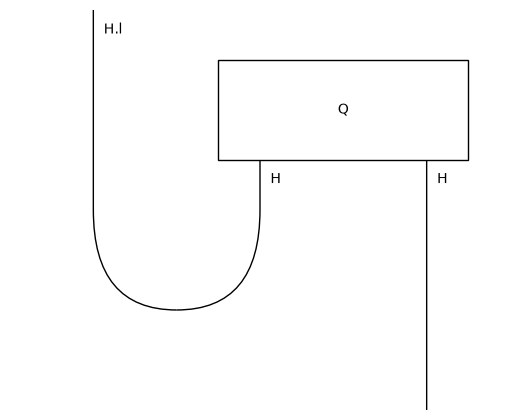

In [6]:
from discopy import rigid
Q_state = ((R >> Sw) @ R) >> times2                                       # tau(R) R, (18.48)
Hr = rigid.Ty('H')
Q_box = rigid.Box('Q', rigid.Ty(), Hr @ Hr)
drinfeld = (rigid.Id(Hr.l) @ Q_box) >> (rigid.Cup(Hr.l, Hr) @ rigid.Id(Hr))   # (ev x id) o (id x Q), (18.50)
print('Drinfeld map boundary:', drinfeld.dom, '->', drinfeld.cod)
for n, omega, label in examples:
    mu_arr = [[[int(k == (i + j) % n) for k in range(n)] for j in range(n)] for i in range(n)]
    R_arr = [[omega ** (i * j) / n for j in range(n)] for i in range(n)]
    Fn = tensor.Functor({H: n}, {mu: mu_arr, eta: [int(k == 0) for k in range(n)], R: R_arr}, dom=symmetric.Category(), dtype=complex)
    Q_arr = Fn(Q_state).array
    Gn = tensor.Functor({Hr: n}, {Q_box: Q_arr}, dom=rigid.Category(), dtype=complex)
    Phi = Gn(drinfeld).array
    print('####', label)
    print('Q = tau(R) R, rows g^a and columns g^b, rounded:'); print(np.round(Q_arr, 3))
    print('Q equals 1 x 1:', np.allclose(Q_arr, Fn(one).array))
    print('Drinfeld map, rows: input covector beta^a, columns: output g^b, rounded:'); print(np.round(Phi, 3))
    print('rank', np.linalg.matrix_rank(Phi), 'of', n, '  invertible:', np.linalg.matrix_rank(Phi) == n)
drinfeld.draw(figsize=(5, 4))

**On one-dimensional representations, Lemma 18.6.8.** The characters $\rho_i(g^k)=\omega^{ik}$ are the one-dimensional representations of $\mathbb Z_n$. Applying $\rho_i\otimes\rho_j$ to $R$ gives the invertible endomorphism $R_{V\otimes W}$ of (18.42), here a single number. The cell evaluates it as the state $R$ followed by the two character boxes and finds $\omega^{-ij}$: the braiding of two characters is a phase, with the sign in the exponent fixed by the chosen $R$. This is the structure that §19.6 draws as a crossing.

In [7]:
for n, omega, label in examples:
    R_arr = [[omega ** (i * j) / n for j in range(n)] for i in range(n)]
    characters = [symmetric.Box('rho_%d' % i, H, symmetric.Ty()) for i in range(n)]
    Fc = tensor.Functor({H: n}, {R: R_arr, **{characters[i]: [omega ** (i * k) for k in range(n)] for i in range(n)}}, dom=symmetric.Category(), dtype=complex)
    table = np.array([[Fc(R >> (characters[i] @ characters[j])).array for j in range(n)] for i in range(n)])
    print('####', label)
    print('rho_i x rho_j (R), rounded:'); print(np.round(table, 3))
    print('equals omega^(-ij):', np.allclose(table, [[omega ** (-i * j) for j in range(n)] for i in range(n)]), '  equals omega^(ij):', np.allclose(table, [[omega ** (i * j) for j in range(n)] for i in range(n)]))

#### Z2, equation (18.41)
rho_i x rho_j (R), rounded:
[[ 1.+0.j  1.+0.j]
 [ 1.+0.j -1.+0.j]]
equals omega^(-ij): True   equals omega^(ij): True
#### Z3 with omega = exp(2 pi i / 3)
rho_i x rho_j (R), rounded:
[[ 1. +0.j     1. -0.j     1. +0.j   ]
 [ 1. -0.j    -0.5-0.866j -0.5+0.866j]
 [ 1. +0.j    -0.5+0.866j -0.5-0.866j]]
equals omega^(-ij): True   equals omega^(ij): False


### The Drinfeld double of $S_3$: Example 18.6.18, (18.52)–(18.56), Task 18.6.19

$D(G)=F(G)\otimes\mathbb FG$ has the basis $\delta_a\otimes\beta_b$, so $D(S_3)$ is $36$-dimensional. $S_3$ is the smallest non-abelian group, and $D(S_3)$ is neither commutative nor cocommutative, so this is the example where (18.35) is a real test. The arrays below are the formulas (18.53)–(18.56) written out on the multiplication table of $S_3$; they are supplied data, and everything after them is native. Elements of $S_3$ are permutations of $\{0,1,2\}$ as tuples, with $(gh)(k)=g(h(k))$. Basis element number $6i+j$ is $\delta_{g_i}\otimes\beta_{g_j}$ in the order in which `itertools` lists the permutations, with $g_0=e$.

The $R$ element (18.55) is printed as $\sum_c\delta_c\otimes\beta_e\otimes\delta_e\otimes\beta_c$. The cells keep that array as `R as printed` and also the array with the unit $\sum_h\delta_h$ of $F(G)$ in the third slot, $\sum_c(\delta_c\otimes\beta_e)\otimes(1\otimes\beta_c)$, as `R`. The second law of (18.36) and invertibility decide between them below.

A product in $H\otimes H\otimes H$ as drawn in the earlier cells puts six wires of dimension $36$ side by side, which is $36^6$ numbers. The laws (18.36) are therefore drawn in a four-wire form: $R_{13}R_{23}=R_1\otimes R'_1\otimes R_2R'_2$ because the middle factor of $R_{13}$ and the first factor of $R_{23}$ are $1$, and $R_{13}R_{12}=R_1R'_1\otimes R'_2\otimes R_2$. The first check below is that on $\mathbb Z_3$ the four-wire pictures evaluate to the same arrays as the six-wire pictures above.

In [8]:
import itertools
S3 = list(itertools.permutations(range(3)))
e3 = (0, 1, 2)
times = {(g, h): tuple(g[h[k]] for k in range(3)) for g in S3 for h in S3}
inverse = {g: h for g in S3 for h in S3 if times[(g, h)] == e3}
pairs = [(a, b) for a in S3 for b in S3]
slot = {ab: i for i, ab in enumerate(pairs)}
N = len(pairs)
mu_D = np.zeros((N, N, N), dtype=int)                 # (18.53): (delta_a beta_b)(delta_c beta_d) = [a = b c b^-1] delta_a beta_{bd}
for a, b in pairs:
    for c, d in pairs:
        if a == times[(times[(b, c)], inverse[b])]:
            mu_D[slot[(a, b)], slot[(c, d)], slot[(a, times[(b, d)])]] = 1
eta_D = np.array([int(b == e3) for a, b in pairs])     # unit: sum_c delta_c beta_e
Delta_D = np.zeros((N, N, N), dtype=int)              # (18.54)
for a, b in pairs:
    for c in S3:
        Delta_D[slot[(a, b)], slot[(c, b)], slot[(times[(inverse[c], a)], b)]] = 1
epsilon_D = np.array([int(a == e3) for a, b in pairs])
s_D = np.zeros((N, N), dtype=int)
for a, b in pairs:
    s_D[slot[(a, b)], slot[(times[(times[(inverse[b], inverse[a])], b)], inverse[b])]] = 1
R_printed_D = np.zeros((N, N), dtype=int)             # (18.55) as printed
R_D = np.zeros((N, N), dtype=int)                     # with the unit of F(G) in the third slot
for c in S3:
    R_printed_D[slot[(c, e3)], slot[(e3, c)]] = 1
    for h in S3:
        R_D[slot[(c, e3)], slot[(h, c)]] = 1
nu_D = np.array([int(b == inverse[a]) for a, b in pairs])         # (18.56)
nu_inverse_D = np.array([int(b == a) for a, b in pairs])
Lambda_D = np.array([int(a == e3) for a, b in pairs])             # integral candidate sum_b delta_e beta_b
lambda_D = np.array([int(b == e3) for a, b in pairs])             # cointegral candidate: coefficient of beta_e
R_printed = symmetric.Box('R as printed', symmetric.Ty(), H @ H)
nu = symmetric.Box('nu', symmetric.Ty(), H)
nu_inverse = symmetric.Box('nu^-1', symmetric.Ty(), H)
Lam = symmetric.Box('Lambda', symmetric.Ty(), H)
lam = symmetric.Box('lambda', H, symmetric.Ty())
FD = tensor.Functor({H: N}, {mu: mu_D, eta: eta_D, Delta: Delta_D, epsilon: epsilon_D, s: s_D, R: R_D, R_printed: R_printed_D, nu: nu_D, nu_inverse: nu_inverse_D, Lam: Lambda_D, lam: lambda_D}, dom=symmetric.Category(), dtype=int)
print('dimension of D(S3):', N, '; nonzero entries of mu, Delta:', int(mu_D.sum()), int(Delta_D.sum()))
print('Hopf algebra laws, native diagrams evaluated on all basis elements:')
print('  associative:', FD((mu @ I) >> mu) == FD((I @ mu) >> mu), '; unit:', FD((eta @ I) >> mu) == FD(I) and FD((I @ eta) >> mu) == FD(I))
print('  coassociative:', FD(Delta >> (Delta @ I)) == FD(Delta >> (I @ Delta)), '; counit:', FD(Delta >> (epsilon @ I)) == FD(I) and FD(Delta >> (I @ epsilon)) == FD(I))
print('  antipode axiom, both sides:', FD(Delta >> (s @ I) >> mu) == FD(epsilon >> eta) and FD(Delta >> (I @ s) >> mu) == FD(epsilon >> eta))
basis = [symmetric.Box('x%d' % i, symmetric.Ty(), H) for i in range(N)]
FB = tensor.Functor({H: N}, {mu: mu_D, Delta: Delta_D, **{basis[i]: [int(j == i) for j in range(N)] for i in range(N)}}, dom=symmetric.Category(), dtype=int)
bialgebra = all(FB((basis[i] @ basis[(7 * i + 3) % N]) >> mu >> Delta) == FB((basis[i] @ basis[(7 * i + 3) % N]) >> (Delta @ Delta) >> (I @ Sw @ I) >> (mu @ mu)) for i in range(0, N, 3))
print('  Delta(xy) = Delta(x)Delta(y) on twelve chosen pairs:', bialgebra)


dimension of D(S3): 36 ; nonzero entries of mu, Delta: 216 216
Hopf algebra laws, native diagrams evaluated on all basis elements:
  associative: True ; unit: True
  coassociative: True ; counit: True
  antipode axiom, both sides: True
  Delta(xy) = Delta(x)Delta(y) on twelve chosen pairs: True


Z3: four-wire pictures agree with the six-wire pictures: True True
#### R with the unit of F(G)
(18.36) first law: True ; second law: True
R (s x id)(R) = 1 x 1: True ; (s x id)(R) R = 1 x 1: True
#### R as printed in (18.55)
(18.36) first law: True ; second law: False
R (s x id)(R) = 1 x 1: False ; (s x id)(R) R = 1 x 1: False


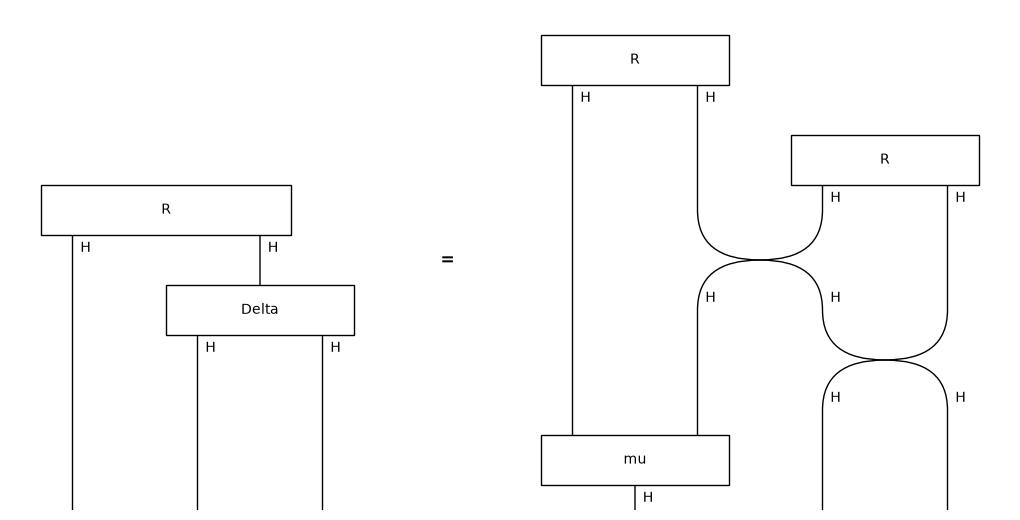

In [9]:
law1_right4 = (R @ R) >> (I @ Sw @ I) >> (I @ I @ mu)                      # R13 R23 = R1 (x) R'1 (x) R2 R'2
law2_right4 = (R @ R) >> (I @ Sw @ I) >> (I @ I @ Sw) >> (mu @ I @ I)         # R13 R12 = R1 R'1 (x) R'2 (x) R2
n, omega = 3, np.exp(2j * np.pi / 3)
F3 = tensor.Functor({H: n}, {mu: [[[int(k == (i + j) % n) for k in range(n)] for j in range(n)] for i in range(n)], eta: [1, 0, 0], Delta: [[[int(i == j == k) for k in range(n)] for j in range(n)] for i in range(n)], R: [[omega ** (i * j) / n for j in range(n)] for i in range(n)]}, dom=symmetric.Category(), dtype=complex)
print('Z3: four-wire pictures agree with the six-wire pictures:', np.allclose(F3(law1_right4).array, F3(law1_right).array), np.allclose(F3(law2_right4).array, F3(law2_right).array))
Equation(law2_left, law2_right4, symbol='=').draw(figsize=(10, 5))
R_inverse4 = R >> (s @ I)
for label, Rbox in [('R with the unit of F(G)', R), ('R as printed in (18.55)', R_printed)]:
    first = FD(Rbox >> (Delta @ I)) == FD((Rbox @ Rbox) >> (I @ Sw @ I) >> (I @ I @ mu))
    second = FD(Rbox >> (I @ Delta)) == FD((Rbox @ Rbox) >> (I @ Sw @ I) >> (I @ I @ Sw) >> (mu @ I @ I))
    print('####', label)
    print('(18.36) first law:', first, '; second law:', second)
    print('R (s x id)(R) = 1 x 1:', FD((Rbox @ (Rbox >> (s @ I))) >> times2) == FD(eta @ eta), '; (s x id)(R) R = 1 x 1:', FD(((Rbox >> (s @ I)) @ Rbox) >> times2) == FD(eta @ eta))


In [10]:
FB35 = tensor.Functor({H: N}, {mu: mu_D, Delta: Delta_D, R: R_D, R_printed: R_printed_D, **{basis[i]: [int(j == i) for j in range(N)] for i in range(N)}}, dom=symmetric.Category(), dtype=int)
print('(18.34) D(S3) is cocommutative:', FD(Delta >> Sw) == FD(Delta), '; commutative:', FD(mu) == FD(Sw >> mu))
for label, Rbox in [('R with the unit of F(G)', R), ('R as printed', R_printed)]:
    holds = all(FB35(((x >> Delta >> Sw) @ Rbox) >> times2) == FB35((Rbox @ (x >> Delta)) >> times2) for x in basis)
    print('(18.35) tau(Delta(x)) R = R Delta(x) on all 36 basis elements,', label + ':', holds)
x5 = basis[5]
print('Example: x5 = delta_', pairs[5][0], 'beta_', pairs[5][1], '; tau(Delta(x5)) == Delta(x5):', FB35(x5 >> Delta >> Sw) == FB35(x5 >> Delta))


(18.34) D(S3) is cocommutative: False ; commutative: False
(18.35) tau(Delta(x)) R = R Delta(x) on all 36 basis elements, R with the unit of F(G): True
(18.35) tau(Delta(x)) R = R Delta(x) on all 36 basis elements, R as printed: True
Example: x5 = delta_ (0, 1, 2) beta_ (2, 1, 0) ; tau(Delta(x5)) == Delta(x5): True


**What the two arrays show.** With the unit of $F(G)$ in the third slot, both laws (18.36) hold, $R$ is invertible, and (18.35) holds on all $36$ basis elements of a Hopf algebra that is neither commutative nor cocommutative, so the law is now tested with content. With (18.55) exactly as printed, the first law and (18.35) still hold but the second law fails and $R$ is not invertible, so that element is not an $R$-matrix. The notebook therefore uses $\sum_c(\delta_c\otimes\beta_e)\otimes(1\otimes\beta_c)$ and records the printed form as a proposed correction to SMSA, not as an established statement. The remaining claims of 18.6.18 and Task 18.6.19 are checked next: the monodromy matrix, the Drinfeld map (invertible, so $D(S_3)$ is factorizable), the ribbon element (18.56) against (18.49), the two-sided integral and cointegral, and the Frobenius map (17.57) with its composite with the Drinfeld map, Remark 18.6.16.

Q = tau(R) R: nonzero entries 36 ; equals 1 x 1: False
Drinfeld map H* -> H, rank: 36 of 36 ; invertible, so D(S3) is factorizable: True
For comparison, with R as printed the Drinfeld map has rank 1
Frobenius map Psi (17.57) rank: 36 ; Psi then its inverse is the identity: True
Remark 18.6.16, Drinfeld map after Frobenius map, H -> H: boundary H -> H ; rank 36 ; invertible: True


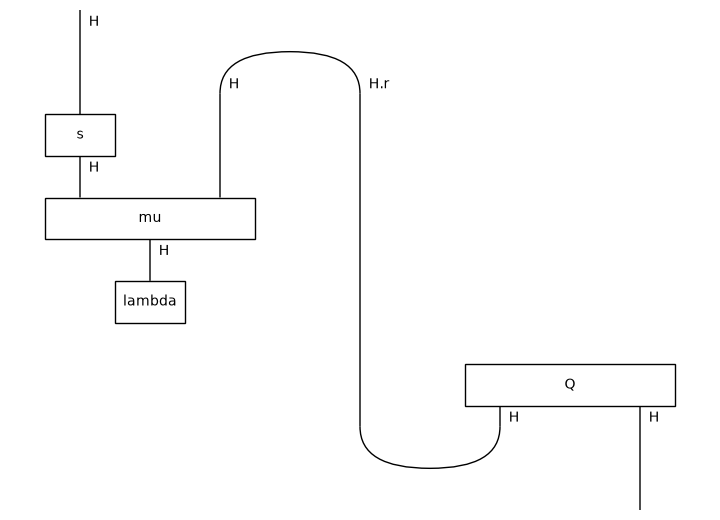

In [11]:
from discopy import compact
Q_D = FD(Q_state).array                                              # tau(R) R, (18.48)
print('Q = tau(R) R: nonzero entries', int(Q_D.sum()), '; equals 1 x 1:', np.array_equal(Q_D, FD(eta @ eta).array))
HD = compact.Ty('H')
Q_c = compact.Box('Q', compact.Ty(), HD @ HD)
mu_c, s_c, Delta_c = compact.Box('mu', HD @ HD, HD), compact.Box('s', HD, HD), compact.Box('Delta', HD, HD @ HD)
lam_c, Lam_c = compact.Box('lambda', HD, compact.Ty()), compact.Box('Lambda', compact.Ty(), HD)
FC = tensor.Functor({HD: N}, {Q_c: Q_D, mu_c: mu_D, s_c: s_D, Delta_c: Delta_D, lam_c: lambda_D, Lam_c: Lambda_D}, dom=compact.Category(), dtype=int)
drinfeld_D = (compact.Id(HD.l) @ Q_c) >> (compact.Cup(HD.l, HD) @ compact.Id(HD))                   # (18.50)
Phi = FC(drinfeld_D).array
print('Drinfeld map H* -> H, rank:', np.linalg.matrix_rank(Phi), 'of', N, '; invertible, so D(S3) is factorizable:', np.linalg.matrix_rank(Phi) == N)
Q_printed = FD(((R_printed >> Sw) @ R_printed) >> times2).array
print('For comparison, with R as printed the Drinfeld map has rank', np.linalg.matrix_rank(Q_printed))
frobenius_D = (compact.Id(HD) @ compact.Cap(HD, HD.r)) >> (s_c @ compact.Id(HD @ HD.r)) >> (mu_c @ compact.Id(HD.r)) >> (lam_c @ compact.Id(HD.r))   # (17.57), as in smsa_17_03
frobenius_inverse_D = (compact.Id(HD.r) @ (Lam_c >> Delta_c)) >> (compact.Cup(HD.r, HD) @ compact.Id(HD))
print('Frobenius map Psi (17.57) rank:', np.linalg.matrix_rank(FC(frobenius_D).array), '; Psi then its inverse is the identity:', np.array_equal(FC(frobenius_D >> frobenius_inverse_D).array, np.eye(N, dtype=int)))
fourier = frobenius_D >> drinfeld_D
print('Remark 18.6.16, Drinfeld map after Frobenius map, H -> H: boundary', fourier.dom, '->', fourier.cod, '; rank', np.linalg.matrix_rank(FC(fourier).array), '; invertible:', np.linalg.matrix_rank(FC(fourier).array) == N)
fourier.draw(figsize=(7, 5))


(18.56) ribbon element nu, checks of (18.49):
  central, nu x = x nu as maps H -> H: True
  invertible, nu nu^-1 = 1 with nu^-1 = sum_c delta_c beta_c: True
  epsilon(nu) = 1: True ; s(nu) = nu: True
  Delta(nu) = Q^-1 (nu x nu), tested as Q Delta(nu) = nu x nu: True ; also Delta(nu) Q = nu x nu: True
Integral Lambda = sum_b delta_e beta_b, (17.50) and its right version: True
Cointegral lambda = coefficient of beta_e, (17.52) and its right version: True
lambda(Lambda) = 1 ; nonzero, as Proposition 17.3.8 needs


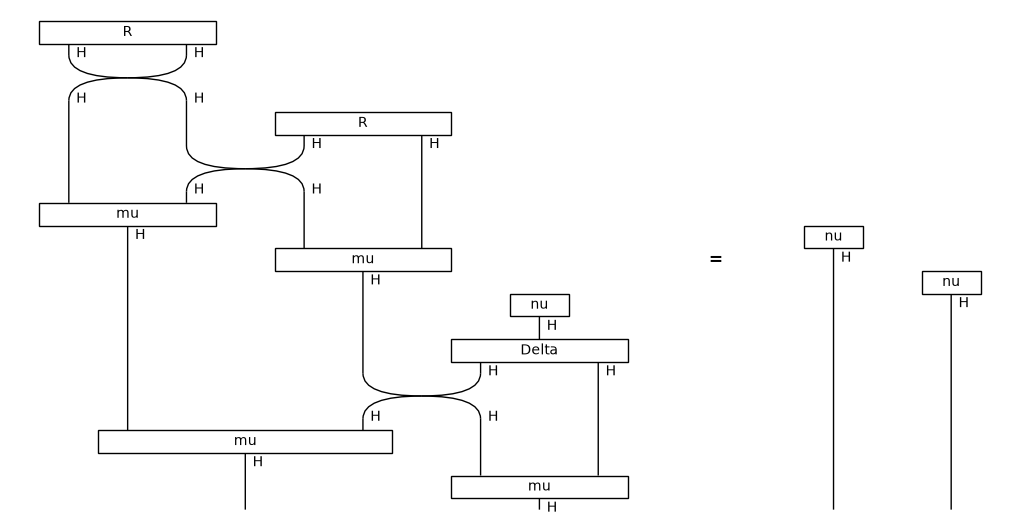

In [12]:
print('(18.56) ribbon element nu, checks of (18.49):')
print('  central, nu x = x nu as maps H -> H:', FD((nu @ I) >> mu) == FD((I @ nu) >> mu))
print('  invertible, nu nu^-1 = 1 with nu^-1 = sum_c delta_c beta_c:', FD((nu @ nu_inverse) >> mu) == FD(eta))
print('  epsilon(nu) = 1:', int(FD(nu >> epsilon).array) == 1, '; s(nu) = nu:', FD(nu >> s) == FD(nu))
ribbon_left = (Q_state @ (nu >> Delta)) >> times2                     # Q Delta(nu), (18.49) multiplied by Q
ribbon_right = nu @ nu
Equation(ribbon_left, ribbon_right, symbol='=').draw(figsize=(10, 5))
print('  Delta(nu) = Q^-1 (nu x nu), tested as Q Delta(nu) = nu x nu:', FD(ribbon_left) == FD(ribbon_right), '; also Delta(nu) Q = nu x nu:', FD(((nu >> Delta) @ Q_state) >> times2) == FD(ribbon_right))
print('Integral Lambda = sum_b delta_e beta_b, (17.50) and its right version:', FD((I @ Lam) >> mu) == FD(epsilon >> Lam) and FD((Lam @ I) >> mu) == FD(epsilon >> Lam))
print('Cointegral lambda = coefficient of beta_e, (17.52) and its right version:', FD(Delta >> (lam @ I)) == FD(lam >> eta) and FD(Delta >> (I @ lam)) == FD(lam >> eta))
print('lambda(Lambda) =', int(FD(Lam >> lam).array), '; nonzero, as Proposition 17.3.8 needs')


**Scope.** The laws (18.36), invertibility, the monodromy (18.48), the Drinfeld map (18.50) and the braiding on characters are evaluated in two abelian group algebras, where (18.35) cannot distinguish the two coproduct orders, and in the Drinfeld double of $S_3$, where it is not. The $D(S_3)$ identities are evaluated on integer arrays, while matrix ranks are computed numerically. The earlier $\mathbb Z_3$ phase checks use numerical comparisons. The bialgebra law of $D(S_3)$ is evaluated on twelve chosen pairs of basis elements, not on all $1296$. The deformed enveloping algebras of Example 18.6.9 are outside this finite setting.